# Laboratorio 10 – Comparación de modelos de clasificación

**Curso:** Software Inteligente · **Autora:** Angela Jara· **Fecha:** 27/10/2026

## 0. Objetivo y trazabilidad

**Objetivo.** Comparar cuatro modelos de clasificación para predecir si una paciente presenta
diabetes, elegir el mejor mediante validación cruzada, diagnosticar su ajuste (subajuste/sobreajuste),
reentrenarlo sin validación cruzada, evaluarlo una sola vez con el 20 % de datos reservados e
interpretar cómo puede utilizarse dentro de un software inteligente.

**Decisiones.**
- Se eligió **clasificación** (y no regresión) porque el laboratorio exige las métricas **ROC y AUC**,
  que solo están definidas para clasificadores.
- Se usa el cTelco Customer Churnonjunto **Pima Indians Diabetes** (768 pacientes, 8 variables clínicas, objetivo binario):
  es pequeño, público, anonimizado, con un desbalance moderado de clases (~35 % positivos) y un
  problema real de calidad de datos (ceros imposibles) que debe tratarse sin fuga de información.

**Trazabilidad de requisitos del laboratorio**

| # | Requisito (enunciado) | Sección(es) |
|---|---|---|
| 1 | Probar 4 modelos de clasificación, elegidos arbitrariamente | 6, 8 |
| 2 | Aplicar 4 métricas idóneas de acuerdo a los modelos | 7, 8 |
| 3 | Durante el entrenamiento activar cross validation | 8 |
| 4 | Elegir el mejor modelo durante el entrenamiento | 9 |
| 5 | Agregar las métricas ROC y AUC | 10, 12 |
| 6 | Mostrar las gráficas del mejor modelo sobre underfitting y overfitting | 11 |
| 7 | Reentrenar el modelo elegido sin cross validation y probar con el 20 % | 12 |
| 8 | Interpretar el modelo elegido como utilizable para el software inteligente | 13, 14, 15 |

## 1. Configuración

In [1]:
import hashlib
import platform
import warnings
from datetime import date
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    learning_curve,
    train_test_split,
    validation_curve,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

# Configuración global del experimento
SEMILLA = 42
TEST_SIZE = 0.2
N_FOLDS = 5
CLASE_POSITIVA = 1
RUTA_DATOS = Path("data/diabetes.csv")
RUTA_MODELO = Path("models/modelo_diabetes.joblib")
SHA256_DATOS = "27939f6c904b6c58a3ae9fe48a50cefadd42b46ce92ebad9cb4114334b28ee66"
# En estas columnas un 0 es fisiológicamente imposible: representa un dato faltante
COLUMNAS_CERO_INVALIDO = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
METRICAS = ["accuracy", "precision", "recall", "f1"]
NOMBRES_METRICAS = {"accuracy": "Exactitud", "precision": "Precisión", "recall": "Sensibilidad (recall)",
                    "f1": "F1", "roc_auc": "ROC-AUC"}

ETIQUETAS_ES = {
    "Pregnancies": "Embarazos",
    "Glucose": "Glucosa",
    "BloodPressure": "Presión diastólica",
    "SkinThickness": "Pliegue cutáneo",
    "Insulin": "Insulina",
    "BMI": "IMC",
    "DiabetesPedigreeFunction": "Antecedente familiar",
    "Age": "Edad",
    "Outcome": "Diabetes",
}

np.random.seed(SEMILLA)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | "
      f"pandas {pd.__version__} | numpy {np.__version__}")

Python 3.14.4 | scikit-learn 1.9.1 | pandas 3.1.0 | numpy 2.5.4


## 2. Carga y descripción de los datos

**Fuente.** *Pima Indians Diabetes Database*, recolectada por el National Institute of Diabetes and
Digestive and Kidney Diseases (NIDDK) y publicada por Smith et al. (1988); difundida por el UCI
Machine Learning Repository y Kaggle (`uciml/pima-indians-diabetes-database`, licencia CC0). La copia
local se obtuvo del espejo público
`https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv`
(SHA-256 del original `6bfe5d0f…54af`), agregando la cabecera de columnas de Kaggle.

Todas las pacientes son mujeres de ascendencia pima de al menos 21 años.

| Columna | Nombre en español | Unidad / significado | Rango válido |
|---|---|---|---|
| `Pregnancies` | Embarazos | número de embarazos | 0–17 (el 0 es válido) |
| `Glucose` | Glucosa | glucosa plasmática a las 2 h de una prueba oral de tolerancia (mg/dL) | > 0 |
| `BloodPressure` | Presión diastólica | presión arterial diastólica (mm Hg) | > 0 |
| `SkinThickness` | Pliegue cutáneo | grosor del pliegue del tríceps (mm) | > 0 |
| `Insulin` | Insulina | insulina sérica a las 2 h (µU/mL) | > 0 |
| `BMI` | IMC | índice de masa corporal (kg/m²) | > 0 |
| `DiabetesPedigreeFunction` | Antecedente familiar | puntaje de historia familiar de diabetes | > 0 |
| `Age` | Edad | años | ≥ 21 |
| `Outcome` | Diabetes | **objetivo**: 1 = con diabetes, 0 = sin diabetes | {0, 1} |

In [2]:
sha = hashlib.sha256(RUTA_DATOS.read_bytes()).hexdigest()
assert sha == SHA256_DATOS, f"El archivo de datos cambió (SHA-256 {sha})"

df = pd.read_csv(RUTA_DATOS)

COLUMNAS_ESPERADAS = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin",
                      "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]
assert df.shape == (768, 9)
assert list(df.columns) == COLUMNAS_ESPERADAS
assert df["Outcome"].value_counts().to_dict() == {0: 500, 1: 268}
assert df.isna().sum().sum() == 0

print(f"Dimensiones: {df.shape[0]} filas × {df.shape[1]} columnas · SHA-256 verificado")
df.head()

Dimensiones: 768 filas × 9 columnas · SHA-256 verificado


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.dtypes.rename('tipo').to_frame()

,tipo
Pregnancies,int64
Glucose,int64
BloodPressure,int64
SkinThickness,int64
Insulin,int64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64


## 3. Análisis exploratorio

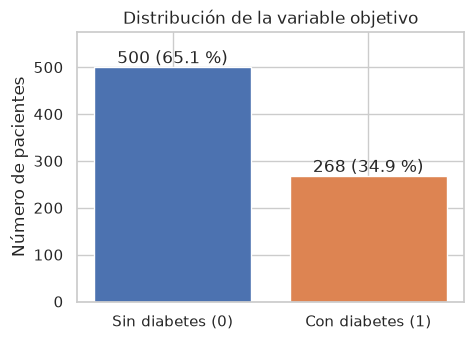

In [4]:
conteo = df["Outcome"].value_counts().sort_index()
porcentaje = conteo / conteo.sum() * 100

fig, ax = plt.subplots(figsize=(5, 3.5))
barras = ax.bar(["Sin diabetes (0)", "Con diabetes (1)"], conteo.values, color=["#4C72B0", "#DD8452"])
for barra, n, p in zip(barras, conteo.values, porcentaje.values):
    ax.annotate(f"{n} ({p:.1f} %)", (barra.get_x() + barra.get_width() / 2, n),
                ha="center", va="bottom")
ax.set_title("Distribución de la variable objetivo")
ax.set_ylabel("Número de pacientes")
ax.set_ylim(0, conteo.max() * 1.15)
plt.show()

In [5]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


In [6]:
ceros = (df[COLUMNAS_CERO_INVALIDO] == 0).sum()
tabla_ceros = pd.DataFrame({
    "Variable": [ETIQUETAS_ES[c] for c in COLUMNAS_CERO_INVALIDO],
    "Ceros inválidos": ceros.values,
    "% del total": (ceros.values / len(df) * 100).round(1),
}, index=COLUMNAS_CERO_INVALIDO)
assert ceros.to_dict() == {"Glucose": 5, "BloodPressure": 35, "SkinThickness": 227, "Insulin": 374, "BMI": 11}
tabla_ceros

,Variable,Ceros inválidos,% del total
Glucose,Glucosa,5,0.7
BloodPressure,Presión diastólica,35,4.6
SkinThickness,Pliegue cutáneo,227,29.6
Insulin,Insulina,374,48.7
BMI,IMC,11,1.4


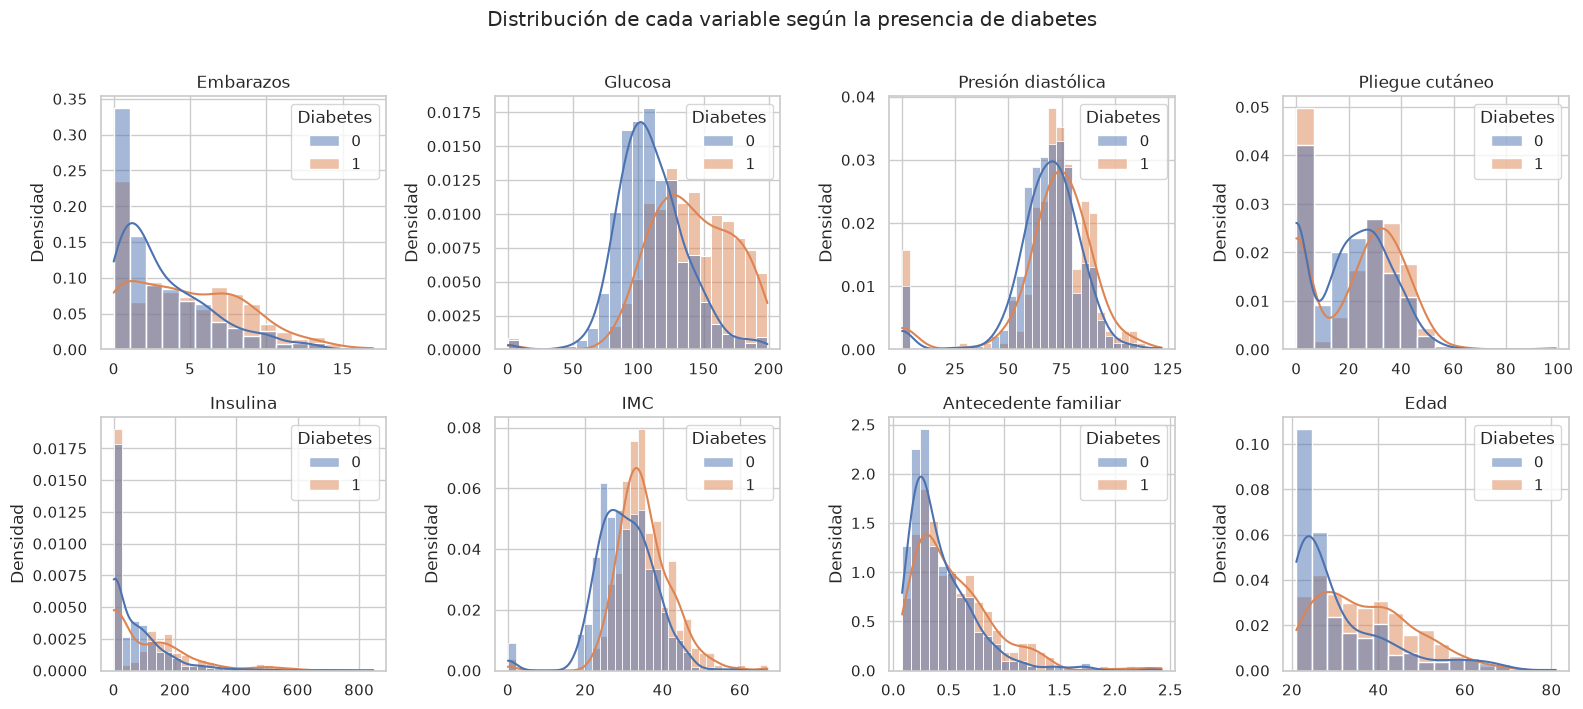

In [7]:
variables = [c for c in df.columns if c != "Outcome"]
fig, ejes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(ejes.ravel(), variables):
    sns.histplot(data=df, x=col, hue="Outcome", kde=True, stat="density", common_norm=False,
                 palette={0: "#4C72B0", 1: "#DD8452"}, ax=ax)
    ax.set_title(ETIQUETAS_ES[col])
    ax.set_xlabel("")
    ax.set_ylabel("Densidad")
    ax.get_legend().set_title("Diabetes")
fig.suptitle("Distribución de cada variable según la presencia de diabetes", y=1.01)
plt.tight_layout()
plt.show()

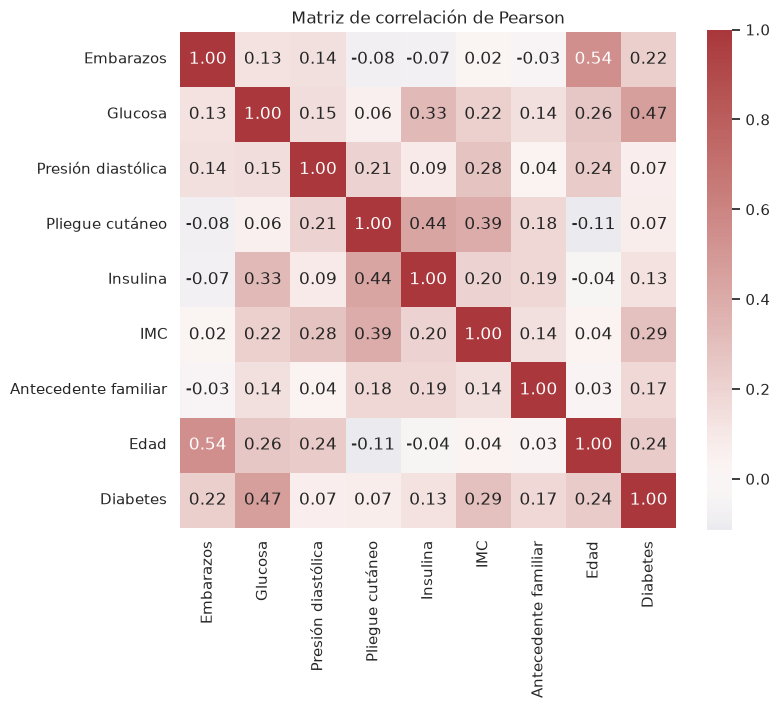

In [8]:
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(df.rename(columns=ETIQUETAS_ES).corr(), annot=True, fmt=".2f", cmap="vlag",
            center=0, square=True, ax=ax)
ax.set_title("Matriz de correlación de Pearson")
plt.show()

**Hallazgos del análisis exploratorio**

- **Desbalance moderado:** 500 pacientes sin diabetes (65,1 %) frente a 268 con diabetes (34,9 %). Un clasificador trivial que siempre prediga “sin diabetes” tendría 65 % de exactitud, por lo que la exactitud no basta para comparar modelos.
- **Ceros imposibles:** insulina (374 ceros, 48,7 %) y pliegue cutáneo (227, 29,6 %) tienen mucha información faltante; presión (35), IMC (11) y glucosa (5) muy poca. Se imputan con la mediana dentro del pipeline (sección 5); la alta proporción imputada en insulina es una limitación del estudio.
- **Variables más asociadas a la diabetes:** la **glucosa** es la que mejor separa las clases (correlación 0,47 con el objetivo; mediana 140 mg/dL en diabéticas vs. 107 en no diabéticas), seguida de **IMC** (0,29), **edad** (0,24) y **embarazos** (0,22). Presión diastólica y pliegue cutáneo apenas se relacionan con el objetivo (0,07).

## 4. Partición entrenamiento/prueba (80/20)

In [9]:
X = df.drop(columns="Outcome")
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEMILLA
)

assert (len(X_train), len(X_test)) == (614, 154)
assert abs(y_train.mean() - y.mean()) < 0.01 and abs(y_test.mean() - y.mean()) < 0.01
assert X_train.index.intersection(X_test.index).empty

pd.DataFrame({
    "Pacientes": [len(y), len(y_train), len(y_test)],
    "Con diabetes": [y.sum(), y_train.sum(), y_test.sum()],
    "% con diabetes": [round(v * 100, 1) for v in (y.mean(), y_train.mean(), y_test.mean())],
}, index=["Total", "Entrenamiento (80 %)", "Prueba (20 %)"])

,Pacientes,Con diabetes,% con diabetes
Total,768,268,34.9
Entrenamiento (80 %),614,214,34.9
Prueba (20 %),154,54,35.1


La partición es **estratificada**: ambos subconjuntos conservan la proporción ≈ 35 % de pacientes con
diabetes. El **20 % de prueba queda apartado y no se vuelve a usar hasta la sección 12**; toda la
comparación de modelos, las curvas de diagnóstico y la elección del umbral se hacen solo con el 80 %.

## 5. Preprocesamiento

In [10]:
def crear_preprocesador():
    # Los ceros imposibles se tratan como faltantes y se imputan con la mediana;
    # Pipeline garantiza que mediana y escalado se aprendan solo con datos de entrenamiento.
    imputacion = ColumnTransformer(
        [("ceros_a_mediana", SimpleImputer(missing_values=0, strategy="median"), COLUMNAS_CERO_INVALIDO)],
        remainder="passthrough",
        verbose_feature_names_out=False,
    )
    return Pipeline([("imputacion", imputacion), ("escalado", StandardScaler())]).set_output(transform="pandas")


crear_preprocesador()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputacion', ...), ('escalado', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ceros_a_mediana', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbose_feature_names_out: 

- En `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` y `BMI` un valor 0 es imposible en una
  persona viva; se interpreta como **dato faltante** y se reemplaza por la **mediana**, robusta ante la
  asimetría de insulina y pliegue cutáneo. En `Pregnancies` el 0 es un valor válido y se conserva.
- Luego se **estandarizan** las variables (media 0, desviación 1): es imprescindible para la Regresión
  Logística y KNN (basados en coeficientes y distancias) e inocuo para los modelos de árboles.
- Ambos pasos viven **dentro del pipeline de cada modelo**. Así, en cada pliegue de la validación
  cruzada la mediana y el escalado se calculan solo con las filas de entrenamiento de ese pliegue,
  evitando **fuga de información** hacia los datos de validación o de prueba.

## 6. Modelos candidatos

In [11]:
def crear_pipeline(clasificador):
    return Pipeline([("prep", crear_preprocesador()), ("clf", clasificador)])


MODELOS = {
    "Regresión Logística": crear_pipeline(LogisticRegression(max_iter=1000, random_state=SEMILLA)),
    "KNN": crear_pipeline(KNeighborsClassifier(n_neighbors=15)),
    "Bosque Aleatorio": crear_pipeline(RandomForestClassifier(n_estimators=300, max_depth=6, random_state=SEMILLA)),
    "Gradient Boosting": crear_pipeline(GradientBoostingClassifier(
        n_estimators=150, max_depth=2, learning_rate=0.05, random_state=SEMILLA)),
}
# Orden de simplicidad / interpretabilidad usado para desempatar
COMPLEJIDAD = {"Regresión Logística": 1, "KNN": 2, "Bosque Aleatorio": 3, "Gradient Boosting": 4}

# Mismos pliegues estratificados para todas las comparaciones
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEMILLA)
list(MODELOS)

['Regresión Logística', 'KNN', 'Bosque Aleatorio', 'Gradient Boosting']

Se eligieron cuatro modelos de **familias distintas** para que la comparación sea informativa. Los
hiperparámetros son valores por defecto o sencillos, fijados de antemano (sin búsqueda exhaustiva),
pensados para no sobreajustar con solo 614 filas de entrenamiento:

| Modelo | Familia | Parámetros | Razón |
|---|---|---|---|
| Regresión Logística | lineal | `max_iter=1000` | línea base interpretable; produce probabilidades bien calibradas |
| KNN | basado en instancias | `n_neighbors=15` | sin supuestos de forma; k = 15 suaviza la frontera (k = 5 sobreajusta con pocos datos) |
| Bosque Aleatorio | ensamble *bagging* | `n_estimators=300`, `max_depth=6` | capta no linealidades e interacciones; la profundidad limitada controla la varianza |
| Gradient Boosting | ensamble *boosting* | `n_estimators=150`, `max_depth=2`, `learning_rate=0.05` | corrige errores secuencialmente; árboles poco profundos y tasa baja contra el sobreajuste |

## 7. Métricas y criterio de selección

La clase positiva es **1 = con diabetes**. Las cuatro métricas idóneas para un clasificador binario
con clases desbalanceadas son:

| Métrica | Fórmula | Significado clínico |
|---|---|---|
| **Exactitud** (*accuracy*) | (VP + VN) / total | proporción de pacientes bien clasificadas |
| **Precisión** | VP / (VP + FP) | de las pacientes señaladas como diabéticas, cuántas lo son realmente |
| **Sensibilidad** (*recall*) | VP / (VP + FN) | de las pacientes diabéticas, cuántas detecta el modelo |
| **F1** | media armónica de precisión y sensibilidad | equilibrio entre no alarmar en falso y no dejar casos sin detectar |

La exactitud por sí sola es engañosa: un modelo que diga siempre “sin diabetes” acertaría el 65 %
sin detectar a ninguna paciente enferma. Por eso se complementa con precisión, sensibilidad y F1, y se
añade **ROC-AUC** (sección 10), que mide la capacidad de separar las clases con cualquier umbral.

**Criterio de selección (fijado antes de ver los resultados):**
1. Gana el modelo con **mayor F1 medio** en la validación cruzada.
2. Se consideran **empatados** los modelos cuyo F1 medio está a menos de una desviación estándar del mejor.
3. Entre empatados gana el de **mayor ROC-AUC medio**; si persiste el empate, el **más simple**
   (Regresión Logística < KNN < Bosque Aleatorio < Gradient Boosting).

## 8. Entrenamiento con validación cruzada (5 pliegues estratificados)

In [12]:
resultados = {}
for nombre, pipe in MODELOS.items():
    cvres = cross_validate(pipe, X_train, y_train, cv=cv, scoring=METRICAS + ["roc_auc"],
                           return_train_score=True, n_jobs=-1)
    fila = {}
    for m in METRICAS + ["roc_auc"]:
        fila[f"{m}_media"] = cvres[f"test_{m}"].mean()
        fila[f"{m}_std"] = cvres[f"test_{m}"].std()
    fila["f1_train_media"] = cvres["train_f1"].mean()
    fila["brecha_f1"] = fila["f1_train_media"] - fila["f1_media"]
    resultados[nombre] = fila

resultados_cv = pd.DataFrame(resultados).T
resultados_cv.round(3)

,accuracy_media,accuracy_std,precision_media,precision_std,recall_media,recall_std,f1_media,f1_std,roc_auc_media,roc_auc_std,f1_train_media,brecha_f1
Regresión Logística,0.788,0.019,0.764,0.060,0.575,0.023,0.655,0.024,0.843,0.019,0.669,0.015
KNN,0.769,0.033,0.719,0.083,0.571,0.067,0.632,0.048,0.832,0.030,0.693,0.061
Bosque Aleatorio,0.774,0.011,0.722,0.045,0.580,0.051,0.640,0.021,0.835,0.023,0.838,0.198
Gradient Boosting,0.764,0.020,0.696,0.040,0.575,0.041,0.629,0.036,0.825,0.016,0.786,0.157


In [13]:
# Tabla legible: media ± desviación estándar y mejor modelo por métrica
legible = pd.DataFrame({
    NOMBRES_METRICAS[m]: [f"{r[f'{m}_media']:.3f} ± {r[f'{m}_std']:.3f}" for _, r in resultados_cv.iterrows()]
    for m in METRICAS + ["roc_auc"]
}, index=resultados_cv.index)
legible["F1 entrenamiento"] = resultados_cv["f1_train_media"].round(3)
legible["Brecha F1 (entr. − val.)"] = resultados_cv["brecha_f1"].round(3)
display(legible)
print("Mejor modelo por métrica:")
for m in METRICAS + ["roc_auc"]:
    print(f"  {NOMBRES_METRICAS[m]:<22} → {resultados_cv[f'{m}_media'].idxmax()}")

,Exactitud,Precisión,Sensibilidad (recall),F1,ROC-AUC,F1 entrenamiento,Brecha F1 (entr. − val.)
Regresión Logística,0.788 ± 0.019,0.764 ± 0.060,0.575 ± 0.023,0.655 ± 0.024,0.843 ± 0.019,0.669,0.015
KNN,0.769 ± 0.033,0.719 ± 0.083,0.571 ± 0.067,0.632 ± 0.048,0.832 ± 0.030,0.693,0.061
Bosque Aleatorio,0.774 ± 0.011,0.722 ± 0.045,0.580 ± 0.051,0.640 ± 0.021,0.835 ± 0.023,0.838,0.198
Gradient Boosting,0.764 ± 0.020,0.696 ± 0.040,0.575 ± 0.041,0.629 ± 0.036,0.825 ± 0.016,0.786,0.157


Mejor modelo por métrica:
  Exactitud              → Regresión Logística
  Precisión              → Regresión Logística
  Sensibilidad (recall)  → Bosque Aleatorio
  F1                     → Regresión Logística
  ROC-AUC                → Regresión Logística


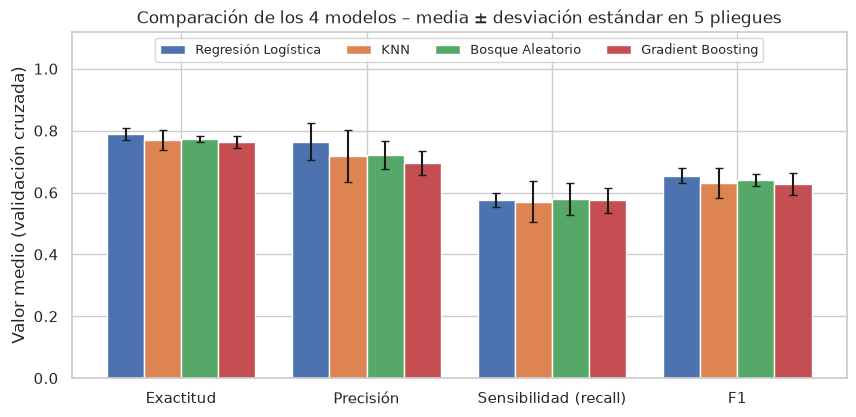

In [14]:
medias = resultados_cv[[f"{m}_media" for m in METRICAS]].to_numpy()
desv = resultados_cv[[f"{m}_std" for m in METRICAS]].to_numpy()
x = np.arange(len(METRICAS))
ancho = 0.2

fig, ax = plt.subplots(figsize=(10, 4.5))
for i, nombre in enumerate(resultados_cv.index):
    ax.bar(x + (i - 1.5) * ancho, medias[i], ancho, yerr=desv[i], capsize=3, label=nombre)
ax.set_xticks(x, [NOMBRES_METRICAS[m] for m in METRICAS])
ax.set_ylim(0, 1.12)
ax.set_ylabel("Valor medio (validación cruzada)")
ax.set_title("Comparación de los 4 modelos – media ± desviación estándar en 5 pliegues")
ax.legend(loc="upper center", ncols=4, fontsize=9)
plt.show()

**Lectura de la validación cruzada**

- La **Regresión Logística** obtiene los mejores promedios en exactitud (0,788), precisión (0,764), F1 (0,655) y ROC-AUC (0,843); el Bosque Aleatorio tiene la sensibilidad más alta (0,580), aunque con diferencias mínimas: los cuatro modelos detectan en torno al 57–58 % de las diabéticas con el umbral 0,5.
- Las diferencias entre modelos son pequeñas (F1 entre 0,629 y 0,655) y del orden de una desviación estándar, algo esperable con 614 pacientes.
- La **brecha F1 entrenamiento − validación** es muy reveladora: 0,015 en Regresión Logística y 0,061 en KNN, frente a 0,198 en Bosque Aleatorio y 0,157 en Gradient Boosting. Los ensambles de árboles memorizan parte del entrenamiento sin traducirlo en mejor validación, es decir, muestran tendencia al sobreajuste.

## 9. Selección del mejor modelo

In [15]:
def seleccionar_mejor(resultados):
    mejor_f1 = resultados["f1_media"].max()
    std_mejor = resultados.loc[resultados["f1_media"].idxmax(), "f1_std"]
    empatados = resultados[resultados["f1_media"] >= mejor_f1 - std_mejor].copy()
    empatados["complejidad"] = [COMPLEJIDAD[n] for n in empatados.index]
    ordenados = empatados.sort_values(["roc_auc_media", "complejidad"], ascending=[False, True])
    return ordenados.index[0], ordenados


NOMBRE_MEJOR, candidatos = seleccionar_mejor(resultados_cv)
mejor_pipeline = MODELOS[NOMBRE_MEJOR]

print(f"Mayor F1 medio: {resultados_cv['f1_media'].idxmax()} ({resultados_cv['f1_media'].max():.3f})")
print(f"Modelos empatados (F1 dentro de 1 desviación estándar): {list(candidatos.index)}")
print(f"\n>>> Modelo elegido: {NOMBRE_MEJOR}")
candidatos[["f1_media", "f1_std", "roc_auc_media", "complejidad"]].round(3)

Mayor F1 medio: Regresión Logística (0.655)
Modelos empatados (F1 dentro de 1 desviación estándar): ['Regresión Logística', 'Bosque Aleatorio', 'KNN']

>>> Modelo elegido: Regresión Logística


,f1_media,f1_std,roc_auc_media,complejidad
Regresión Logística,0.655,0.024,0.843,1
Bosque Aleatorio,0.640,0.021,0.835,3
KNN,0.632,0.048,0.832,2


**Justificación de la elección**

Aplicando el criterio fijado en la sección 7: la Regresión Logística tiene el mayor F1 medio (0,655 ± 0,024). Bosque Aleatorio (0,640) y KNN (0,632) quedan dentro de una desviación estándar y se consideran empatados; Gradient Boosting (0,629) queda fuera. Entre los empatados, la Regresión Logística también tiene el mayor ROC-AUC (0,843 frente a 0,835 y 0,832), por lo que **se elige la Regresión Logística** sin necesidad de recurrir al desempate por simplicidad.

Además de ganar por el criterio, es el modelo con menor brecha entre entrenamiento y validación (0,015), el más simple y el más interpretable, cualidades valiosas para un software de apoyo clínico.

## 10. Curvas ROC y AUC (validación cruzada)

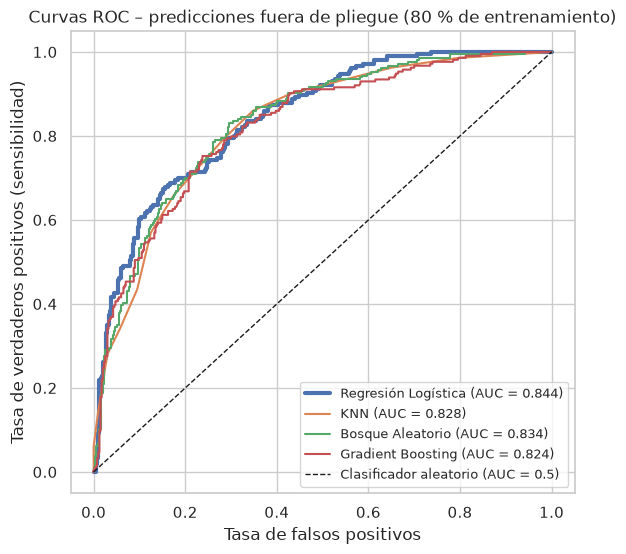

,AUC fuera de pliegue (agregado),AUC media por pliegue
Regresión Logística,0.844,0.843
KNN,0.828,0.832
Bosque Aleatorio,0.834,0.835
Gradient Boosting,0.824,0.825


In [16]:
oof_proba = {}
fig, ax = plt.subplots(figsize=(6.5, 6))
for nombre, pipe in MODELOS.items():
    oof_proba[nombre] = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    fpr, tpr, _ = roc_curve(y_train, oof_proba[nombre])
    auc = roc_auc_score(y_train, oof_proba[nombre])
    ax.plot(fpr, tpr, lw=3 if nombre == NOMBRE_MEJOR else 1.5, label=f"{nombre} (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Clasificador aleatorio (AUC = 0.5)")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos (sensibilidad)")
ax.set_title("Curvas ROC – predicciones fuera de pliegue (80 % de entrenamiento)")
ax.legend(loc="lower right", fontsize=9)
plt.show()

pd.DataFrame({
    "AUC fuera de pliegue (agregado)": {n: roc_auc_score(y_train, p) for n, p in oof_proba.items()},
    "AUC media por pliegue": resultados_cv["roc_auc_media"],
}).round(3)

La curva ROC muestra, para todos los umbrales posibles, el compromiso entre detectar pacientes
diabéticas (eje Y) y generar falsas alarmas (eje X). El **AUC** resume la curva: 0,5 equivale a azar y
1,0 a una separación perfecta. El AUC “agregado” se calcula juntando las predicciones fuera de pliegue
de los 5 pliegues; puede diferir levemente del promedio de los 5 AUC por pliegue porque cada pliegue
tiene una escala de probabilidades ligeramente distinta.

**Interpretación de las curvas ROC**

Los cuatro modelos están claramente por encima de la diagonal del azar, con AUC fuera de pliegue entre 0,824 (Gradient Boosting) y 0,844 (Regresión Logística). Las curvas casi se superponen: ningún modelo domina a los demás en todos los umbrales, lo que confirma que la diferencia entre ellos es pequeña. La Regresión Logística, elegida en la sección 9, mantiene también el mejor AUC (0,844 agregado; 0,843 promedio por pliegue), de modo que su elección es coherente con ambas métricas. Un AUC ≈ 0,84 significa que, tomando al azar una paciente diabética y una no diabética, el modelo asigna mayor probabilidad a la diabética en el 84 % de los casos.

## 11. Diagnóstico de subajuste (underfitting) y sobreajuste (overfitting)

- **Curva de aprendizaje:** F1 en entrenamiento y en validación al aumentar el tamaño de la muestra.
  Si ambas curvas son bajas y cercanas → *subajuste*; si entrenamiento es alto y validación mucho menor
  → *sobreajuste*; si convergen en un valor alto → *buen ajuste*.
- **Curva de validación:** F1 al variar un hiperparámetro de complejidad del modelo elegido. A la
  izquierda (modelo demasiado simple) aparece subajuste; a la derecha (demasiado complejo), sobreajuste.

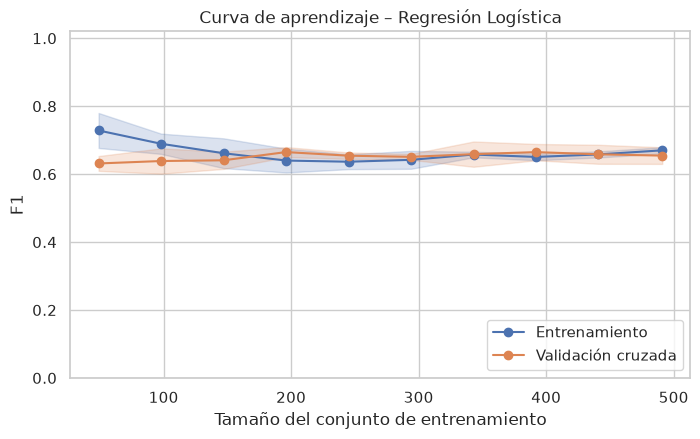

In [17]:
tamanos, train_lc, val_lc = learning_curve(
    mejor_pipeline, X_train, y_train, cv=cv, scoring="f1",
    train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1, shuffle=True, random_state=SEMILLA,
)
train_f1, val_f1 = train_lc.mean(axis=1), val_lc.mean(axis=1)

fig, ax = plt.subplots(figsize=(8, 4.5))
for medias_, desv_, etiqueta, color in [(train_f1, train_lc.std(axis=1), "Entrenamiento", "#4C72B0"),
                                        (val_f1, val_lc.std(axis=1), "Validación cruzada", "#DD8452")]:
    ax.plot(tamanos, medias_, "o-", color=color, label=etiqueta)
    ax.fill_between(tamanos, medias_ - desv_, medias_ + desv_, color=color, alpha=0.2)
ax.set_xlabel("Tamaño del conjunto de entrenamiento")
ax.set_ylabel("F1")
ax.set_ylim(0, 1.02)
ax.set_title(f"Curva de aprendizaje – {NOMBRE_MEJOR}")
ax.legend(loc="lower right")
plt.show()

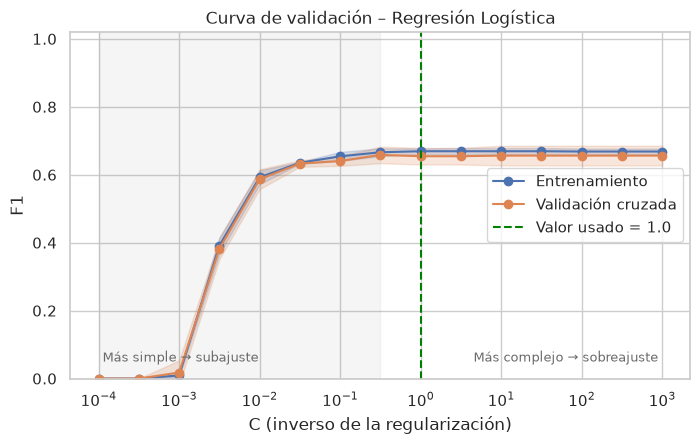

Mejor valor según la curva de validación: 0.31622776601683794 (F1 val. = 0.658)
Valor usado en el modelo: 1.0 (F1 val. = 0.655)


In [18]:
PARAM_VALIDACION = {
    "Regresión Logística": ("clf__C", list(np.logspace(-4, 3, 15)), "C (inverso de la regularización)", True),
    "KNN": ("clf__n_neighbors", list(range(1, 52, 2)), "Número de vecinos k", False),
    "Bosque Aleatorio": ("clf__max_depth", list(range(1, 21)), "Profundidad máxima de los árboles", False),
    "Gradient Boosting": ("clf__max_depth", list(range(1, 9)), "Profundidad máxima de los árboles", False),
}
parametro, rango, etiqueta_x, escala_log = PARAM_VALIDACION[NOMBRE_MEJOR]
valor_usado = mejor_pipeline.get_params()[parametro]

train_vc, val_vc = validation_curve(mejor_pipeline, X_train, y_train, param_name=parametro,
                                    param_range=rango, cv=cv, scoring="f1", n_jobs=-1)
train_vc_m, val_vc_m = train_vc.mean(axis=1), val_vc.mean(axis=1)
mejor_valor_vc = rango[int(np.argmax(val_vc_m))]

fig, ax = plt.subplots(figsize=(8, 4.5))
for medias_, desv_, etiqueta, color in [(train_vc_m, train_vc.std(axis=1), "Entrenamiento", "#4C72B0"),
                                        (val_vc_m, val_vc.std(axis=1), "Validación cruzada", "#DD8452")]:
    ax.plot(rango, medias_, "o-", color=color, label=etiqueta)
    ax.fill_between(rango, medias_ - desv_, medias_ + desv_, color=color, alpha=0.2)
ax.axvline(valor_usado, color="green", ls="--", label=f"Valor usado = {valor_usado}")
# Zona de subajuste: complejidad menor al óptimo de validación; sobreajuste: brecha creciente a la derecha
ax.axvspan(rango[0], mejor_valor_vc, color="grey", alpha=0.08)
ax.text(rango[0], 0.05, " Más simple → subajuste", fontsize=9, color="dimgray")
ax.text(rango[-1], 0.05, "Más complejo → sobreajuste ", fontsize=9, color="dimgray", ha="right")
if escala_log:
    ax.set_xscale("log")
ax.set_xlabel(etiqueta_x)
ax.set_ylabel("F1")
ax.set_ylim(0, 1.02)
ax.set_title(f"Curva de validación – {NOMBRE_MEJOR}")
ax.legend(loc="center right")
plt.show()

print(f"Mejor valor según la curva de validación: {mejor_valor_vc} (F1 val. = {val_vc_m.max():.3f})")
print(f"Valor usado en el modelo: {valor_usado} "
      f"(F1 val. = {val_vc_m[rango.index(valor_usado)] if valor_usado in list(rango) else float('nan'):.3f})")

In [19]:
brecha = train_f1[-1] - val_f1[-1]
if brecha > 0.10:
    veredicto = "Tendencia a SOBREAJUSTE"
elif val_f1[-1] < 0.55 and brecha < 0.05:
    veredicto = "SUBAJUSTE"
else:
    veredicto = "BUEN AJUSTE"
print(f"F1 entrenamiento (tamaño completo): {train_f1[-1]:.3f}")
print(f"F1 validación    (tamaño completo): {val_f1[-1]:.3f}")
print(f"Brecha entrenamiento − validación:  {brecha:.3f}")
print(f"Diagnóstico: {veredicto}  (reglas: brecha > 0.10 → sobreajuste; F1 val. < 0.55 y brecha < 0.05 → subajuste)")

F1 entrenamiento (tamaño completo): 0.670
F1 validación    (tamaño completo): 0.655
Brecha entrenamiento − validación:  0.016
Diagnóstico: BUEN AJUSTE  (reglas: brecha > 0.10 → sobreajuste; F1 val. < 0.55 y brecha < 0.05 → subajuste)


**Interpretación de las gráficas de ajuste**

- **Curva de aprendizaje:** con pocos datos (≈ 50 pacientes) el F1 de entrenamiento (0,73) supera al de validación (0,63), pero desde unas 200 pacientes ambas curvas convergen y se mantienen juntas alrededor de 0,66. Con el conjunto completo la brecha es de solo **0,016** (0,670 vs. 0,655), por lo que **no hay sobreajuste**. El valor de validación (0,655) supera el umbral de 0,55, por lo que tampoco se considera subajuste: el diagnóstico es **buen ajuste**.
- La meseta en ≈ 0,66 indica que **agregar más filas del mismo tipo apenas mejoraría el F1**: el límite está en la información que aportan las 8 variables (y en la frontera lineal), no en la cantidad de datos.
- **Curva de validación (C):** con regularización muy fuerte (C ≤ 10⁻³) el modelo es demasiado simple, predice casi siempre “sin diabetes” y el F1 cae a 0: es la **zona de subajuste**. A partir de C ≈ 0,3 ambas curvas se estabilizan en ≈ 0,66 y permanecen paralelas incluso con C = 1000; un modelo lineal con solo 8 variables no tiene capacidad suficiente para sobreajustar, por eso no aparece una zona de sobreajuste marcada.
- El valor usado, **C = 1,0**, está en la meseta: su F1 de validación (0,655) prácticamente coincide con el máximo de la curva (0,658 con C ≈ 0,32), así que no hacía falta ajustar el hiperparámetro.

## 12. Reentrenamiento sin validación cruzada y prueba con el 20 %

El modelo elegido se **reentrena una sola vez, sin validación cruzada**, con todo el 80 % de
entrenamiento (614 pacientes). A continuación se usa **por primera y única vez** el 20 % de prueba
(154 pacientes) para obtener una estimación imparcial de su desempeño con umbral 0,5.

In [20]:
modelo_final = clone(mejor_pipeline).fit(X_train, y_train)

proba_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= 0.5).astype(int)


def metricas(y_real, y_pred, proba):
    return {
        "accuracy": accuracy_score(y_real, y_pred),
        "precision": precision_score(y_real, y_pred),
        "recall": recall_score(y_real, y_pred),
        "f1": f1_score(y_real, y_pred),
        "roc_auc": roc_auc_score(y_real, proba),
    }


metricas_test = metricas(y_test, pred_test, proba_test)
pd.Series({NOMBRES_METRICAS[k]: v for k, v in metricas_test.items()}, name=f"{NOMBRE_MEJOR} – prueba").round(3).to_frame()

,Regresión Logística – prueba
Exactitud,0.708
Precisión,0.600
Sensibilidad (recall),0.500
F1,0.545
ROC-AUC,0.813


              precision    recall  f1-score   support

Sin diabetes      0.752     0.820     0.785       100
Con diabetes      0.600     0.500     0.545        54

    accuracy                          0.708       154
   macro avg      0.676     0.660     0.665       154
weighted avg      0.699     0.708     0.701       154



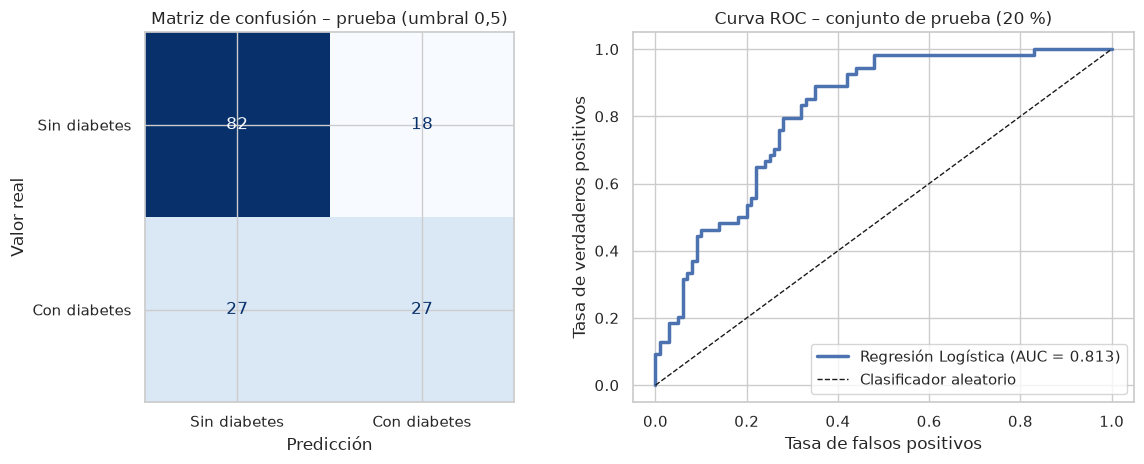

In [21]:
print(classification_report(y_test, pred_test, target_names=["Sin diabetes", "Con diabetes"], digits=3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["Sin diabetes", "Con diabetes"],
                                        cmap="Blues", colorbar=False, ax=ax1)
ax1.set_title("Matriz de confusión – prueba (umbral 0,5)")
ax1.set_xlabel("Predicción")
ax1.set_ylabel("Valor real")

fpr, tpr, _ = roc_curve(y_test, proba_test)
ax2.plot(fpr, tpr, lw=2.5, label=f"{NOMBRE_MEJOR} (AUC = {metricas_test['roc_auc']:.3f})")
ax2.plot([0, 1], [0, 1], "k--", lw=1, label="Clasificador aleatorio")
ax2.set_xlabel("Tasa de falsos positivos")
ax2.set_ylabel("Tasa de verdaderos positivos")
ax2.set_title("Curva ROC – conjunto de prueba (20 %)")
ax2.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [22]:
fila_cv = resultados_cv.loc[NOMBRE_MEJOR]
comparacion = pd.DataFrame({
    "Validación cruzada (media)": [fila_cv[f"{m}_media"] for m in metricas_test],
    "Validación cruzada (std)": [fila_cv[f"{m}_std"] for m in metricas_test],
    "Prueba (20 %)": list(metricas_test.values()),
}, index=[NOMBRES_METRICAS[m] for m in metricas_test])
comparacion["Diferencia (prueba − CV)"] = comparacion["Prueba (20 %)"] - comparacion["Validación cruzada (media)"]
display(comparacion.round(3))

cumple_auc = metricas_test["roc_auc"] >= 0.75
cumple_f1 = abs(metricas_test["f1"] - fila_cv["f1_media"]) <= 0.10
print(f"AUC de prueba ≥ 0.75: {'sí' if cumple_auc else 'no'} ({metricas_test['roc_auc']:.3f})")
print(f"|F1 prueba − F1 CV| ≤ 0.10: {'sí' if cumple_f1 else 'no'} ({abs(metricas_test['f1'] - fila_cv['f1_media']):.3f})")

,Validación cruzada (media),Validación cruzada (std),Prueba (20 %),Diferencia (prueba − CV)
Exactitud,0.788,0.019,0.708,-0.080
Precisión,0.764,0.060,0.600,-0.164
Sensibilidad (recall),0.575,0.023,0.500,-0.075
F1,0.655,0.024,0.545,-0.109
ROC-AUC,0.843,0.019,0.813,-0.030


AUC de prueba ≥ 0.75: sí (0.813)
|F1 prueba − F1 CV| ≤ 0.10: no (0.109)


**Generalización en el conjunto de prueba**

- El **ROC-AUC de prueba es 0,813**, solo 0,030 por debajo de la validación cruzada (0,843): la capacidad del modelo para **ordenar** a las pacientes por riesgo se mantiene en datos nunca vistos y cumple el criterio AUC ≥ 0,75.
- Las métricas que dependen del umbral 0,5 caen más: exactitud 0,708 (−0,080), precisión 0,600 (−0,164), sensibilidad 0,500 (−0,075) y **F1 0,545 (−0,109)**, que excede por 0,009 la tolerancia de 0,10 fijada en la especificación. **Este criterio no se cumple** y se explica así:
  - El conjunto de prueba solo tiene **54 pacientes diabéticas**; cada una equivale a 1,9 puntos de sensibilidad. El error estándar binomial de una sensibilidad de 0,5 con n = 54 es ≈ 0,068 (intervalo del 95 % ≈ ±0,13), de modo que una sola partición de 154 pacientes produce estimaciones muy variables.
  - Como el AUC (independiente del umbral) apenas baja, la caída se concentra en el **umbral 0,5**, que deja sin detectar a 27 de las 54 diabéticas. Ese umbral no es adecuado para tamizaje; la sección 13 propone uno elegido solo con datos de entrenamiento.
- Conclusión: el modelo generaliza su capacidad discriminativa, pero la estimación de F1 con umbral 0,5 obtenida en validación cruzada resultó optimista para esta partición de prueba.

## 13. Interpretación del modelo para el software inteligente

### 13.1 Umbral de decisión recomendado

En un sistema de **tamizaje** (detección temprana) dejar sin detectar a una paciente diabética es más
costoso que derivar a una paciente sana a un examen de laboratorio. Por eso se busca el **umbral más
alto que mantenga una sensibilidad de al menos 80 %**. El umbral se elige con las probabilidades
**fuera de pliegue del 80 % de entrenamiento** (sección 10), nunca con el conjunto de prueba; los
resultados de prueba se muestran solo como información.

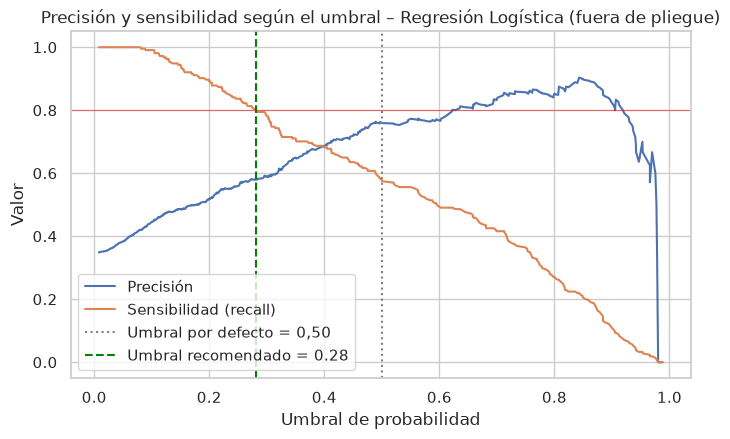

Umbral recomendado (sensibilidad fuera de pliegue ≥ 0.80): 0.281


,"Umbral 0,50",Umbral 0.28
Exactitud,0.708,0.727
Precisión,0.600,0.577
Sensibilidad (recall),0.500,0.833
F1,0.545,0.682
ROC-AUC,0.813,0.813
VP (diabéticas detectadas),27.000,45.000
FN (diabéticas no detectadas),27.000,9.000
FP (falsas alarmas),18.000,33.000
VN (sanas bien clasificadas),82.000,67.000


In [23]:
precision_oof, recall_oof, umbrales_oof = precision_recall_curve(y_train, oof_proba[NOMBRE_MEJOR])
UMBRAL = float(max(u for u, r in zip(umbrales_oof, recall_oof[:-1]) if r >= 0.80))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(umbrales_oof, precision_oof[:-1], label="Precisión")
ax.plot(umbrales_oof, recall_oof[:-1], label="Sensibilidad (recall)")
ax.axvline(0.5, color="gray", ls=":", label="Umbral por defecto = 0,50")
ax.axvline(UMBRAL, color="green", ls="--", label=f"Umbral recomendado = {UMBRAL:.2f}")
ax.axhline(0.80, color="red", lw=0.8, alpha=0.5)
ax.set_xlabel("Umbral de probabilidad")
ax.set_ylabel("Valor")
ax.set_title(f"Precisión y sensibilidad según el umbral – {NOMBRE_MEJOR} (fuera de pliegue)")
ax.legend(loc="lower left")
plt.show()

pred_umbral = (proba_test >= UMBRAL).astype(int)
metricas_umbral = metricas(y_test, pred_umbral, proba_test)
tabla_umbral = pd.DataFrame({"Umbral 0,50": metricas_test, f"Umbral {UMBRAL:.2f}": metricas_umbral})
tabla_umbral.index = [NOMBRES_METRICAS[m] for m in tabla_umbral.index]
for etiqueta, pred in [("Umbral 0,50", pred_test), (f"Umbral {UMBRAL:.2f}", pred_umbral)]:
    vn, fp, fn, vp = confusion_matrix(y_test, pred).ravel()
    tabla_umbral.loc["VP (diabéticas detectadas)", etiqueta] = vp
    tabla_umbral.loc["FN (diabéticas no detectadas)", etiqueta] = fn
    tabla_umbral.loc["FP (falsas alarmas)", etiqueta] = fp
    tabla_umbral.loc["VN (sanas bien clasificadas)", etiqueta] = vn
print(f"Umbral recomendado (sensibilidad fuera de pliegue ≥ 0.80): {UMBRAL:.3f}")
tabla_umbral.round(3)

### 13.2 Influencia de las variables

Se usa la **importancia por permutación** sobre el conjunto de prueba: cuánto empeora el F1 cuando se
desordena aleatoriamente cada variable. Es un análisis *a posteriori* que no modifica el modelo y
funciona para cualquiera de los cuatro algoritmos.

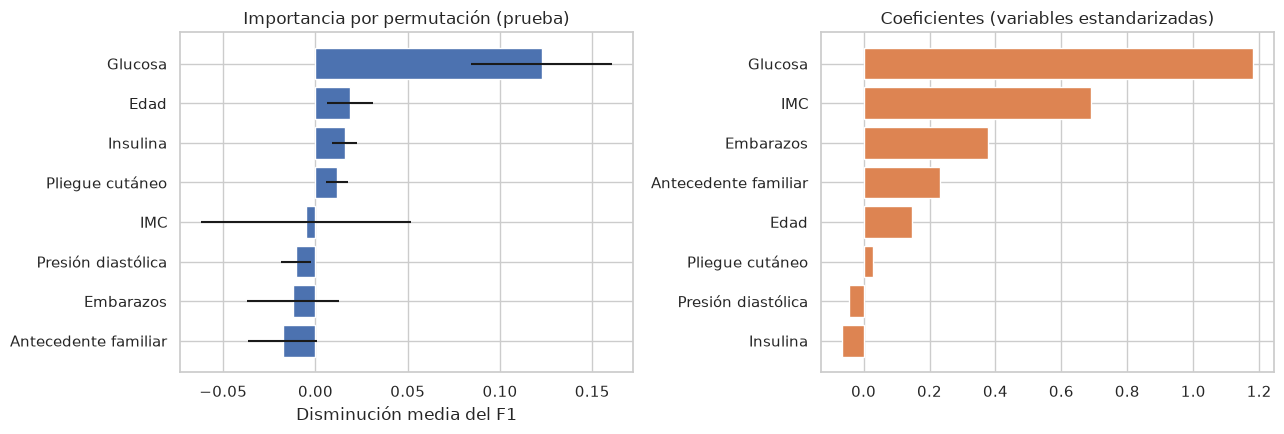

,media,std
Glucosa,0.123,0.038
Edad,0.019,0.012
Insulina,0.016,0.007
Pliegue cutáneo,0.012,0.006
IMC,-0.005,0.057
Presión diastólica,-0.011,0.008
Embarazos,-0.012,0.025
Antecedente familiar,-0.018,0.019


In [24]:
imp = permutation_importance(modelo_final, X_test, y_test, scoring="f1", n_repeats=30,
                             random_state=SEMILLA, n_jobs=-1)
importancias = (pd.DataFrame({"media": imp.importances_mean, "std": imp.importances_std},
                             index=[ETIQUETAS_ES[c] for c in X_test.columns])
                .sort_values("media"))

clf = modelo_final.named_steps["clf"]
nativa = None
if hasattr(clf, "coef_"):
    nativa = ("Coeficientes (variables estandarizadas)", clf.coef_[0])
elif hasattr(clf, "feature_importances_"):
    nativa = ("Importancia por reducción de impureza", clf.feature_importances_)

fig, ejes = plt.subplots(1, 2 if nativa else 1, figsize=(13 if nativa else 7, 4.5), squeeze=False)
ax = ejes[0, 0]
ax.barh(importancias.index, importancias["media"], xerr=importancias["std"], color="#4C72B0")
ax.set_xlabel("Disminución media del F1")
ax.set_title("Importancia por permutación (prueba)")
if nativa:
    nombres_prep = modelo_final.named_steps["prep"].get_feature_names_out()
    serie = pd.Series(nativa[1], index=[ETIQUETAS_ES[c] for c in nombres_prep]).sort_values()
    ejes[0, 1].barh(serie.index, serie.values, color="#DD8452")
    ejes[0, 1].set_title(nativa[0])
plt.tight_layout()
plt.show()
importancias.sort_values("media", ascending=False).round(3)

**Interpretación para el software inteligente**

- **Variables determinantes.** Los coeficientes de la Regresión Logística (sobre variables estandarizadas) muestran que la **glucosa** es, con diferencia, el factor más influyente (+1,18), seguida del **IMC** (+0,69), los **embarazos** (+0,38), el **antecedente familiar** (+0,23) y la **edad** (+0,15); insulina, presión y pliegue cutáneo tienen coeficientes cercanos a 0. La importancia por permutación coincide en lo esencial: desordenar la glucosa reduce el F1 de prueba en 0,123 ± 0,038, mientras que el efecto del resto de variables es pequeño y está dentro del ruido (los valores ligeramente negativos se deben a las solo 154 pacientes de prueba, no a que la variable perjudique). Es **clínicamente plausible**: la glucemia es el criterio diagnóstico de la diabetes, y la obesidad, la edad, la historia familiar y los embarazos (diabetes gestacional) son factores de riesgo reconocidos.
- **Costo de los errores.** Un **falso negativo** es una paciente diabética que el sistema clasifica como sana: no recibe seguimiento y la enfermedad progresa sin tratamiento. Un **falso positivo** solo implica una derivación innecesaria a un análisis de glucosa o HbA1c, de bajo costo. Por eso el software debe priorizar la sensibilidad.
- **Umbral recomendado: 0,28.** Elegido con datos de entrenamiento para asegurar sensibilidad ≥ 80 %. En prueba, comparado con 0,5, eleva la sensibilidad de 0,500 a **0,833** (falsos negativos de 27 a **9**) y el F1 de 0,545 a 0,682, a cambio de pasar de 18 a 33 falsas alarmas (precisión 0,600 → 0,577). Es decir, se detectan 18 diabéticas más a cambio de 15 derivaciones adicionales, un intercambio favorable para tamizaje. El AUC no cambia (0,813) porque no depende del umbral.
- **Limitaciones.** El modelo se entrenó solo con mujeres pima de 21 años o más (768 registros), no debe aplicarse sin revalidar a hombres u otras poblaciones; el 48,7 % de los valores de insulina fueron imputados; la evaluación final se basa en 154 pacientes, por lo que sus métricas tienen una incertidumbre considerable; y es un modelo de **apoyo al tamizaje, no de diagnóstico**.

## 14. Uso del modelo en el software inteligente

In [25]:
RUTA_MODELO.parent.mkdir(exist_ok=True)
artefacto = {
    "pipeline": modelo_final,
    "features": list(X.columns),
    "umbral": UMBRAL,
    "modelo": NOMBRE_MEJOR,
    "metricas_test": {k: round(float(v), 4) for k, v in metricas_test.items()},
    "version_sklearn": sklearn.__version__,
    "fecha": date.today().isoformat(),
}
joblib.dump(artefacto, RUTA_MODELO)

# Simula al software: vuelve a cargar el archivo y verifica que reproduce las predicciones
artefacto = joblib.load(RUTA_MODELO)
assert np.allclose(artefacto["pipeline"].predict_proba(X_test)[:, 1], proba_test)
print(f"Modelo guardado en {RUTA_MODELO} ({RUTA_MODELO.stat().st_size / 1024:.0f} KB) y verificado tras recargarlo")
{k: v for k, v in artefacto.items() if k != "pipeline"}

Modelo guardado en models/modelo_diabetes.joblib (5 KB) y verificado tras recargarlo


{'features': ['Pregnancies',
  'Glucose',
  'BloodPressure',
  'SkinThickness',
  'Insulin',
  'BMI',
  'DiabetesPedigreeFunction',
  'Age'],
 'umbral': 0.2805882977541021,
 'modelo': 'Regresión Logística',
 'metricas_test': {'accuracy': 0.7078,
  'precision': 0.6,
  'recall': 0.5,
  'f1': 0.5455,
  'roc_auc': 0.813},
 'version_sklearn': '1.9.1',
 'fecha': '2026-10-27'}

In [26]:
def predecir_paciente(artefacto, datos):
    faltantes = [c for c in artefacto["features"] if c not in datos]
    if faltantes:
        raise ValueError(f"Faltan datos de la paciente: {faltantes}")
    fila = pd.DataFrame([datos])[artefacto["features"]]
    probabilidad = float(artefacto["pipeline"].predict_proba(fila)[0, 1])
    clase = int(probabilidad >= artefacto["umbral"])
    return {"probabilidad": round(probabilidad, 3), "clase": clase, "riesgo": "alto" if clase else "bajo"}


paciente_nueva = {"Pregnancies": 2, "Glucose": 150, "BloodPressure": 80, "SkinThickness": 30,
                  "Insulin": 0, "BMI": 34.5, "DiabetesPedigreeFunction": 0.6, "Age": 45}
resultado = predecir_paciente(artefacto, paciente_nueva)
print(f"Probabilidad estimada de diabetes: {resultado['probabilidad']:.1%}")
print(f"Riesgo: {resultado['riesgo'].upper()} (umbral {artefacto['umbral']:.2f})")
if resultado["clase"]:
    print("Recomendación: derivar a una prueba de glucosa en ayunas / HbA1c y a evaluación médica.")
else:
    print("Recomendación: mantener controles preventivos habituales.")

try:
    predecir_paciente(artefacto, {"Glucose": 150})
except ValueError as error:
    print(f"\nValidación de entrada: {error}")

Probabilidad estimada de diabetes: 61.4%
Riesgo: ALTO (umbral 0.28)
Recomendación: derivar a una prueba de glucosa en ayunas / HbA1c y a evaluación médica.

Validación de entrada: Faltan datos de la paciente: ['Pregnancies', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


**Integración en el software inteligente.**

1. **Captura:** un formulario solicita las 8 variables clínicas (los valores desconocidos de glucosa,
   presión, pliegue, insulina o IMC pueden enviarse como 0: el pipeline los imputa con la mediana
   aprendida en el entrenamiento).
2. **Validación:** se verifica que estén las 8 variables y en rangos plausibles (`predecir_paciente`
   rechaza entradas incompletas).
3. **Inferencia:** el software carga **un único archivo** (`models/modelo_diabetes.joblib`) que contiene
   preprocesamiento, modelo, umbral y orden de variables, evitando inconsistencias entre entrenamiento y uso.
4. **Respuesta:** muestra la probabilidad, el nivel de riesgo y una recomendación (derivar o no a
   pruebas confirmatorias).
5. **Mantenimiento:** reentrenar cuando se disponga de más datos o de otra población, y monitorear la
   sensibilidad real del sistema.

> ⚠️ **No es un dispositivo de diagnóstico.** Es un modelo educativo de apoyo al tamizaje: su salida
> debe ser confirmada por pruebas clínicas y por un profesional de la salud.

## 15. Conclusiones

1. **Modelo elegido: Regresión Logística.** En validación cruzada estratificada de 5 pliegues obtuvo el mayor F1 (0,655 ± 0,024) y el mayor ROC-AUC (0,843 ± 0,019) de los cuatro modelos, superando a Bosque Aleatorio, KNN y Gradient Boosting, aunque con diferencias pequeñas entre ellos.
2. **Ajuste:** las curvas de aprendizaje y de validación muestran un **buen ajuste** (brecha entrenamiento − validación de 0,016), sin sobreajuste; en cambio, los ensambles de árboles presentaron brechas de 0,16–0,20. El subajuste solo aparece con regularización extrema (C ≤ 10⁻³).
3. **Prueba con el 20 %:** el modelo reentrenado sin validación cruzada mantiene una buena capacidad discriminativa (**AUC 0,813**), aunque con umbral 0,5 su F1 baja a 0,545, en parte por la variabilidad de una muestra de prueba con solo 54 diabéticas.
4. **Uso en el software inteligente:** con el umbral recomendado de **0,28** el sistema detecta el 83 % de las pacientes diabéticas de prueba (45 de 54), lo que lo hace útil como herramienta de **tamizaje** que prioriza a quién derivar a pruebas confirmatorias. El modelo se entrega en un único archivo (`models/modelo_diabetes.joblib`) con preprocesamiento, umbral y orden de variables, y su uso es simple e interpretable (la glucosa y el IMC dominan la predicción).
5. **Siguientes pasos:** validar con datos de otra población, evaluar con validación cruzada repetida o una partición de prueba mayor, probar variables adicionales (p. ej., HbA1c) y calibrar las probabilidades antes de mostrarlas al usuario final.